# Keras Regresión

# 1.Importación librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Creación del modelo

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.optimizers import Adam

In [4]:
model = Sequential()

X_train = pd.read_csv('../data/processed/X_test_binario.csv')
y_train = pd.read_csv('../data/processed/Y_test_binario.csv')
X_test = pd.read_csv('../data/processed/X_test_binario.csv')
y_test = pd.read_csv('../data/processed/Y_test_binario.csv')
#Añadir un número de neuronas similar al número de features en X_train - 7 en el ejemplo
num_neuronas = X_train.shape[1] # con esto se calcula automáticamente la cantidad de neuronas, dado que extrae el dato desde el propio dataset / ESTAS SON LAS CAPAS OCULTAS, con num_neuronas viene la cantidad de neuronas que serán empleadas; ESTE ES EL CORAZÓN DE TODO EL PROCESAMIENTO
model.add(Dense(num_neuronas,activation='relu'))
model.add(Dense(num_neuronas,activation='relu'))
model.add(Dense(num_neuronas,activation='relu'))
model.add(Dense(num_neuronas,activation='relu'))
model.add(Dense(1)) # Indicar tantas neuronas de salida como variables a predecir, en este caso solo 1 variable "buy_price"

model.compile(optimizer='adam',loss='mse')

# 7. Entrenamiento del modelo

In [5]:
model.fit(x=X_train,y=y_train.values,
          validation_data=(X_test,y_test.values), #si indicamos validation_data en cada epoch calcula sobre el conjunto de test el resultado de pérdidas
          batch_size=512,epochs=200) #batch_size es el tamaño de datos que toma en cada cálculo (indicar potencia de 2) / epochs es el número de iteraciones sobre la red neuronal para ajustar los pesos (w) y bias (b)
# Si tengo gráfica, puedo cambiar el batch_size a un 512 para que vaya más rápido

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - loss: 0.5718 - val_loss: 0.4691
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - loss: 0.4691 - val_loss: 0.3938
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - loss: 0.3938 - val_loss: 0.3386
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - loss: 0.3386 - val_loss: 0.2976
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - loss: 0.2976 - val_loss: 0.2668
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - loss: 0.2668 - val_loss: 0.2443
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - loss: 0.2443 - val_loss: 0.2282
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.2282 - val_loss: 0.2173
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - loss: 0.2173 - val_loss: 0.2110
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - loss: 0.2110 - val_loss: 0.2076
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - loss: 0.2076 - val_loss: 0.2065
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - loss: 0.2065

In [6]:
losses = pd.DataFrame(model.history.history)# perdidas de muestro modelo(loss) y el de test(val_loss)

In [7]:
losses

,loss,val_loss
0,0.571781,0.469122
1,0.469122,0.393763
2,0.393763,0.338642
3,0.338642,0.297631
4,0.297631,0.266774
...,...,...
195,0.000003,0.000003
196,0.000003,0.000002
197,0.000002,0.000002
198,0.000002,0.000002


<Axes: >

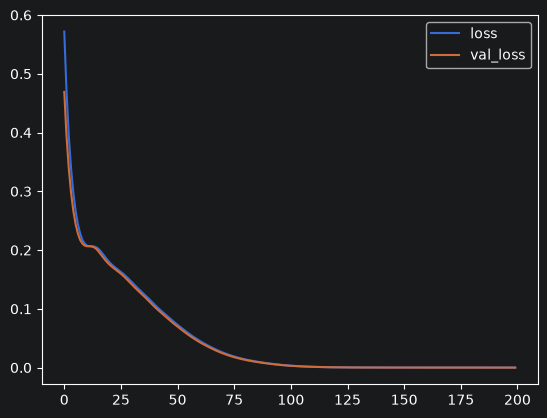

In [8]:
losses.plot() # este es el gráfico del GRADIENTE DESCENDIENTE, si vamos por buen camino, se tendría que ver así, caso contrario hay que devolverse a chequear todo

# 8. Evaluación del modelo

https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics

In [9]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,explained_variance_score

## 8.1 Predicción sobre el conjunto de Test

In [10]:
X_test

,duracion_meses,monto_credito,tasa_cuotas,tiempo_residencia,edad,creditos_existentes,personas_dependientes,estado_cuenta_A11,estado_cuenta_A12,estado_cuenta_A13,...,vivienda_A152,vivienda_A153,trabajo_A171,trabajo_A172,trabajo_A173,trabajo_A174,telefono_A191,telefono_A192,trabajador_extranjero_A201,trabajador_extranjero_A202
0,0.294118,0.124642,1.000000,1.000000,0.500000,0.333333,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0.117647,0.045460,0.666667,0.333333,0.142857,0.333333,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,0.294118,0.192914,1.000000,1.000000,0.553571,0.000000,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
3,0.073529,0.101499,0.333333,0.333333,0.321429,0.000000,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
4,0.029412,0.004739,1.000000,1.000000,0.589286,0.333333,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.147059,0.028984,1.000000,0.333333,0.142857,0.333333,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
196,0.088235,0.141724,0.000000,0.333333,0.232143,0.000000,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
197,0.470588,0.270168,1.000000,0.333333,0.178571,0.000000,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
198,0.647059,0.327750,1.000000,1.000000,0.553571,0.000000,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [11]:
predictions = model.predict(X_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


In [12]:
mean_absolute_error(y_test,predictions)

0.0007242639549076557

In [13]:
np.sqrt(mean_squared_error(y_test,predictions))

np.float64(0.0014594763281228185)

In [14]:
explained_variance_score(y_test,predictions) #Calcula la covarianza en y_test (real) y la predicción, cuanto más cercano a 1 mejor (significa que conforme más aumenta o disminuye el valor real, más aumenta o disminuye el valor predecido)

0.9999898672103882

# VOY POR ACÁ

In [15]:
mean_absolute_error(y_test,predictions)/df['buy_price'].mean() #¿En qué porcentaje nos estamos equivaocando respecto al valor medio?

NameError: name 'df' is not defined

In [136]:
mean_absolute_error(y_test,predictions)/df['buy_price'].median() #¿En qué porcentaje nos estamos equivaocando respecto al valor mediana?

np.float64(0.2886156866776316)

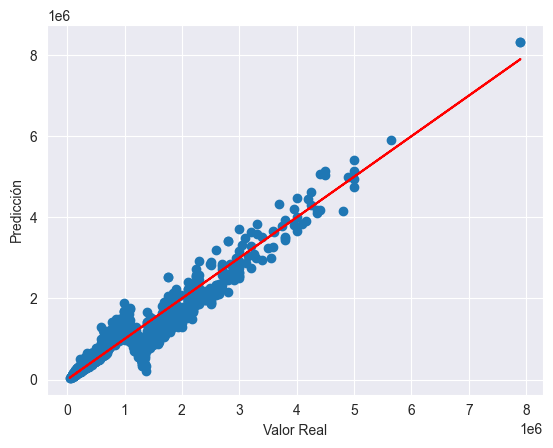

In [137]:
# Visualizar nuestra predicción
plt.scatter(y_test,predictions)
plt.xlabel("Valor Real")
plt.ylabel("Predicción")

# Predicción perfecta
plt.plot(y_test,y_test,'r')

In [138]:
errors = y_test.values.reshape(y_test.shape[0], 1) - predictions #rotar y_test para poder comparar con predictions

C:\Users\ogonzalezc\AppData\Local\Temp\ipykernel_2444\3079573258.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(errors) #Idealmente debe estar concentrado el error en 0


<Axes: ylabel='Density'>

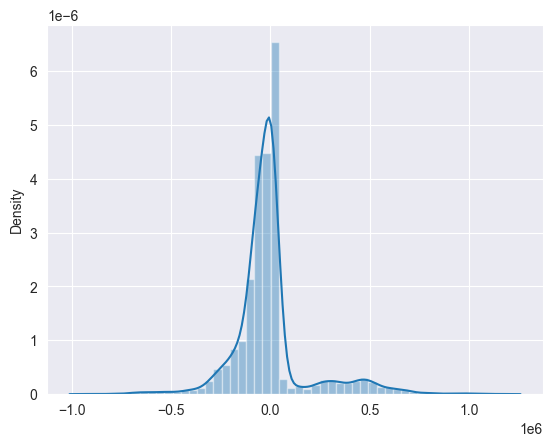

In [139]:
sns.distplot(errors) #Idealmente debe estar concentrado el error en 0

## 8.2 Predicción sobre nuevos datos

In [140]:
#Lectura datos a predecir
df_pred = pd.read_excel('./viviendas_Madrid.xlsx',sheet_name='Datos_Predecir')

In [141]:
df_pred = df_pred[df.columns] #Filtramos el dataframe predicción para quedarnos con las mismas columnas de interés que el df histórico
df_pred

,sq_mt_built,n_rooms,n_bathrooms,is_floor_under,rent_price,buy_price,is_new_development,has_parking
0,65,2,1.0,False,420,NaN,False,False
1,72,3,1.0,False,650,NaN,False,False
2,97,2,2.0,False,730,NaN,False,False
3,63,2,1.0,True,590,NaN,False,False
4,107,2,2.0,False,1000,NaN,False,True
5,125,4,2.0,False,890,NaN,False,True
6,130,5,2.0,False,885,NaN,False,True
7,135,3,2.0,False,912,NaN,False,False
8,76,3,2.0,False,970,NaN,False,True
9,87,2,1.0,False,701,NaN,False,False


In [146]:
X_pred = df_pred.drop('buy_price',axis=1) #Eliminamos la columna objetivo (vacía) si la hubiera en nuestro df con los datos a predecir
X_pred

,sq_mt_built,n_rooms,n_bathrooms,is_floor_under,rent_price,is_new_development,has_parking
0,65,2,1.0,False,420,False,False
1,72,3,1.0,False,650,False,False
2,97,2,2.0,False,730,False,False
3,63,2,1.0,True,590,False,False
4,107,2,2.0,False,1000,False,True
5,125,4,2.0,False,890,False,True
6,130,5,2.0,False,885,False,True
7,135,3,2.0,False,912,False,False
8,76,3,2.0,False,970,False,True
9,87,2,1.0,False,701,False,False


In [147]:
X_pred = scaler.transform(X_pred)
X_pred

array([[0.04989817, 0.08333333, 0.        , 0.        , 0.03199109,
        0.        , 0.        ],
       [0.05702648, 0.125     , 0.        , 0.        , 0.05029445,
        0.        , 0.        ],
       [0.08248473, 0.08333333, 0.07692308, 0.        , 0.05666083,
        0.        , 0.        ],
       [0.04786151, 0.08333333, 0.        , 1.        , 0.04551966,
        0.        , 0.        ],
       [0.09266802, 0.08333333, 0.07692308, 0.        , 0.07814738,
        0.        , 1.        ],
       [0.11099796, 0.16666667, 0.07692308, 0.        , 0.0693936 ,
        0.        , 1.        ],
       [0.11608961, 0.20833333, 0.07692308, 0.        , 0.0689957 ,
        0.        , 1.        ],
       [0.12118126, 0.125     , 0.07692308, 0.        , 0.07114436,
        0.        , 0.        ],
       [0.0610998 , 0.125     , 0.07692308, 0.        , 0.07575999,
        0.        , 1.        ],
       [0.07230143, 0.08333333, 0.        , 0.        , 0.05435302,
        0.        , 0. 

In [148]:
#Realizamos predicción
resultado = model.predict(X_pred)
resultado

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


array([[ 67147.81],
       [122006.62],
       [215531.9 ],
       [110124.91],
       [326279.34],
       [291790.28],
       [284067.1 ],
       [305451.6 ],
       [281218.2 ],
       [158790.19]], dtype=float32)

In [149]:
#Unimos en un dataframe los datos a predecir con su predicción
df_pred['PREDICCIÓN']=pd.DataFrame(resultado)
df_pred

,sq_mt_built,n_rooms,n_bathrooms,is_floor_under,rent_price,buy_price,is_new_development,has_parking,PREDICCIÓN
0,65,2,1.0,False,420,NaN,False,False,67147.812500
1,72,3,1.0,False,650,NaN,False,False,122006.617188
2,97,2,2.0,False,730,NaN,False,False,215531.906250
3,63,2,1.0,True,590,NaN,False,False,110124.906250
4,107,2,2.0,False,1000,NaN,False,True,326279.343750
5,125,4,2.0,False,890,NaN,False,True,291790.281250
6,130,5,2.0,False,885,NaN,False,True,284067.093750
7,135,3,2.0,False,912,NaN,False,False,305451.593750
8,76,3,2.0,False,970,NaN,False,True,281218.187500
9,87,2,1.0,False,701,NaN,False,False,158790.187500


In [ ]:
#Guardar y cargar el modelo para posterior uso

In [150]:
from tensorflow.keras.models import load_model

In [158]:
model.save('modelo_pred_vivienda.keras')

In [163]:
#Cargar modelo para posterior uso

In [156]:
modelo_cargado = load_model('modelo_pred_vivienda.keras')

C:\Users\ogonzalezc\OneDrive - tse.go.cr\Documentos\CUC\2025\II Cuatrimestre 2025\Inteligencia Artificial Aplicada\Semana 3\Ejercicios ANN\.venv1\Lib\site-packages\keras\src\saving\saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
model.save('modelo_pred_vivienda.keras')

# Paso final

In [ ]:
#
resultado = model.predict(x_pred)
resultado

#### Cuando vamos a darle nuevos datos para que haga predicciones, esos datos tengo que escalarlos para que funcione correctamente, sino, explota